# 10. Xu comparison

This notebook compares the tissue-level metrics exported by `7_test_8020_split_eval.ipynb` with Xu `TableS6` from `Table0_S1-S8_Combined20220114.xlsx`.

Notebook 7 now writes tissue results for every evaluated model source in a TableS6-compatible CSV:

- `results_comparison_all_models/eval_metrics_by_tissue_tableS6_format.csv`
- fallback per-source files: `<source>__eval_metrics_by_tissue_tableS6_format.csv`
- fallback ENet-only file: `enet_zbig_k5000_tissue_metrics_xu_format.csv`

The comparison joins rows by normalized tissue and proteomics platform, then reports matched rows, unmatched diagnostics, metric deltas, summary statistics, and plots. Positive Pearson/r deltas favor the notebook-7 model; negative RMSE/MAE/MSE deltas favor the notebook-7 model.

## 1. Setup and paths

In [6]:
from pathlib import Path
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 180,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
})

CWD = Path.cwd().resolve()
PROJECT_MARKERS = [
    "val_data",
    "processed_data",
    "res_enet_zbig",
    "results_comparison_all_models",
    "Table0_S1-S8_Combined20220114.xlsx",
]

def _candidate_score(path: Path) -> int:
    return sum((path / marker).exists() for marker in PROJECT_MARKERS)

_project_candidates = []
for p in [CWD, *CWD.parents]:
    if p.exists() and p not in _project_candidates:
        _project_candidates.append(p)
ROOT_DIR = max(_project_candidates, key=_candidate_score)

# Optional hard override if needed.
# ROOT_DIR = Path(r"C:\Users\hp\Desktop\new_pRNA").resolve()

RESULTS_DIR = ROOT_DIR / "results_comparison_all_models"
METRICS_TISSUE_TABLES6_CSV = RESULTS_DIR / "eval_metrics_by_tissue_tableS6_format.csv"
METRICS_TISSUE_CSV = RESULTS_DIR / "eval_metrics_by_tissue.csv"
ENET_ZBIG_TABLES6_CSV = RESULTS_DIR / "enet_zbig_k5000_tissue_metrics_xu_format.csv"

# Optional: set this manually if the Xu supplementary Excel is outside the project folder.
# MANUAL_XU_XLSX_PATH = r"C:\Users\hp\Desktop\new_pRNA\Table0_S1-S8_Combined20220114.xlsx"
MANUAL_XU_XLSX_PATH = None

OUT_DIR = ROOT_DIR / "xu_comparison_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TABLES6_COLUMNS = [
    "ShortName", "common", "totalRNA", "totalprotein", "pearson", "spearman",
    "tissue", "samples", "platform", "complexity_RNA", "complexity_protein",
    "mae", "r", "rmse", "tissue specific protein", "tissue_specific_protein",
]

def find_xu_excel():
    def _validate_candidates(candidates):
        checked = []
        seen = set()
        for p in candidates:
            if not p:
                continue
            try:
                rp = Path(p).expanduser().resolve()
            except Exception:
                continue
            if rp in seen or not rp.exists():
                continue
            seen.add(rp)
            try:
                xl = pd.ExcelFile(rp)
                checked.append((rp, xl.sheet_names))
                if "TableS6" in xl.sheet_names:
                    return rp, checked
            except Exception as exc:
                checked.append((rp, f"unreadable: {exc}"))
        return None, checked

    explicit_candidates = []
    if MANUAL_XU_XLSX_PATH:
        explicit_candidates.append(Path(MANUAL_XU_XLSX_PATH).expanduser())
    if os.environ.get("XU_XLSX_PATH"):
        explicit_candidates.append(Path(os.environ["XU_XLSX_PATH"]).expanduser())

    likely_names = [
        "Table0_S1-S8_Combined20220114.xlsx",
        "Table0_S1-S8_Combined20220114.xls",
    ]
    search_roots = []
    for p in [ROOT_DIR, CWD, CWD.parent, ROOT_DIR.parent]:
        if p.exists() and p not in search_roots:
            search_roots.append(p)

    fast_candidates = list(explicit_candidates)
    for base in search_roots:
        for name in likely_names:
            fast_candidates.append(base / name)

    found, checked = _validate_candidates(fast_candidates)
    if found is not None:
        return found, checked

    recursive = []
    for base in search_roots:
        try:
            recursive.extend(base.rglob("*.xlsx"))
            recursive.extend(base.rglob("*.xls"))
        except Exception:
            pass
    recursive = sorted(
        set(recursive),
        key=lambda p: (
            "combined20220114" not in p.name.lower(),
            "table0" not in p.name.lower(),
            len(str(p)),
        ),
    )
    found, checked_recursive = _validate_candidates(recursive)
    return found, checked + checked_recursive

XLSX_PATH, XLSX_CHECKED = find_xu_excel()
HAS_XU_TABLE = XLSX_PATH is not None

print("Current working directory:", CWD)
print("Detected project root:", ROOT_DIR)
print("Results directory:", RESULTS_DIR)
print("Main all-model tissue file:", METRICS_TISSUE_TABLES6_CSV)
print("Output folder:", OUT_DIR)
if HAS_XU_TABLE:
    print("Xu Excel file:", XLSX_PATH)
else:
    print("Xu Excel file: NOT FOUND")
    print("Place Table0_S1-S8_Combined20220114.xlsx in the project root, or set MANUAL_XU_XLSX_PATH in this cell.")
    for path, sheets in XLSX_CHECKED[:10]:
        print(" -", path, "->", sheets)


Current working directory: C:\Users\hp\Desktop\new_pRNA\notebooks2
Detected project root: C:\Users\hp\Desktop\new_pRNA
Results directory: C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models
Main all-model tissue file: C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\eval_metrics_by_tissue_tableS6_format.csv
Output folder: C:\Users\hp\Desktop\new_pRNA\xu_comparison_outputs
Xu Excel file: C:\Users\hp\Desktop\new_pRNA\Table0_S1-S8_Combined20220114.xlsx


## 2. Load Xu TableS6

In [7]:
if not HAS_XU_TABLE:
    raise FileNotFoundError(
        "Xu TableS6 workbook was not found. Put Table0_S1-S8_Combined20220114.xlsx in the project root "
        "or set MANUAL_XU_XLSX_PATH."
    )

xl = pd.ExcelFile(XLSX_PATH)
print("Sheets:", xl.sheet_names)
if "TableS6" not in xl.sheet_names:
    raise ValueError("Expected a sheet named 'TableS6' in the Xu Excel file.")

xu_raw = pd.read_excel(XLSX_PATH, sheet_name="TableS6")
xu = xu_raw.copy()
xu.columns = [str(c).strip() for c in xu.columns]
if "ShortName" not in xu.columns:
    raise ValueError("TableS6 does not contain the expected 'ShortName' column.")

# Keep the original TableS6 shape and add explicit Xu-prefixed metric aliases.
xu = xu[[c for c in TABLES6_COLUMNS if c in xu.columns]].copy()
for c in ["common", "totalRNA", "totalprotein", "pearson", "spearman", "samples", "mae", "r", "rmse", "tissue_specific_protein"]:
    if c in xu.columns:
        xu[c] = pd.to_numeric(xu[c], errors="coerce")

xu = xu.dropna(subset=["ShortName"]).copy()
xu["xu_dataset"] = xu["ShortName"].astype(str)
xu["xu_proxy_pearson"] = xu.get("pearson", np.nan)
xu["xu_proxy_spearman"] = xu.get("spearman", np.nan)
xu["xu_r"] = xu.get("r", np.nan)
xu["xu_mae"] = xu.get("mae", np.nan)
xu["xu_rmse"] = xu.get("rmse", np.nan)
xu["xu_mse"] = xu["xu_rmse"] ** 2

print("Xu TableS6 rows:", xu.shape[0])
display(xu.head(10))


Sheets: ['TableS1', 'TableS2', 'TableS3', 'TableS4', 'TableS5', 'TableS6', 'TableS7', 'TableS8']
Xu TableS6 rows: 20


,ShortName,common,totalRNA,totalprotein,pearson,spearman,tissue,samples,platform,complexity_RNA,...,rmse,tissue specific protein,tissue_specific_protein,xu_dataset,xu_proxy_pearson,xu_proxy_spearman,xu_r,xu_mae,xu_rmse,xu_mse
0,CO_labelfree,2113,14959,2244,0.229183,0.235372,colon,86,labelfree,0.393815,...,0.956563,757,757,CO_labelfree,0.229183,0.235372,0.259475,0.751304,0.956563,0.915014
1,BN_labelfree,4234,14408,4385,0.151748,0.152212,brain,71,labelfree,0.717820,...,0.880700,1850,1850,BN_labelfree,0.151748,0.152212,0.397859,0.680979,0.880700,0.775633
2,PR_labelfree,3445,21601,3537,0.226986,0.224086,prostate,65,labelfree,0.449804,...,0.932632,1060,1060,PR_labelfree,0.226986,0.224086,0.297630,0.745326,0.932632,0.869802
3,LV_labelfree,2315,14180,2354,0.412494,0.386321,liver,62,labelfree,0.434155,...,0.813337,757,757,LV_labelfree,0.412494,0.386321,0.509291,0.641711,0.813337,0.661516
4,LU_labelfree,2209,16597,2272,0.118115,0.104513,lung,76,labelfree,0.525222,...,0.958027,712,712,LU_labelfree,0.118115,0.104513,0.326919,0.770595,0.958027,0.917815
5,LV_tmt,6195,12559,6472,0.448624,0.390871,liver,318,tmt,0.578292,...,0.694758,2067,2067,LV_tmt,0.448624,0.390871,0.697328,0.529236,0.694758,0.482689
6,CO_tmt,4201,12932,4375,0.289840,0.280570,colon,95,tmt,0.446393,...,0.949505,1392,1392,CO_tmt,0.289840,0.280570,0.327762,0.752258,0.949505,0.901560
7,RC_tmt,6933,14636,7146,0.510334,0.531295,renal,185,tmt,0.598990,...,0.640897,2292,2292,RC_tmt,0.510334,0.531295,0.734394,0.510158,0.640897,0.410749
8,PBN_tmt,6184,18197,6425,0.460076,0.428887,pedbrain,188,tmt,0.628463,...,0.728755,2313,2313,PBN_tmt,0.460076,0.428887,0.654054,0.567398,0.728755,0.531084
9,BR_tmt,5698,10163,7581,0.443950,0.449147,breast,122,tmt,0.357786,...,0.803906,2450,2450,BR_tmt,0.443950,0.449147,0.553957,0.628184,0.803906,0.646264


## 3. Load tissue metrics exported by notebook 7

In [8]:
def load_notebook7_tissue_tables6():
    """Load all-model TableS6-format tissue metrics from notebook 7.

    Preferred file: eval_metrics_by_tissue_tableS6_format.csv.
    Fallback: concatenate per-source TableS6-format files.
    Final fallback: ENet zbig k5000 TableS6-format file.
    """
    checked = []
    if METRICS_TISSUE_TABLES6_CSV.exists():
        df = pd.read_csv(METRICS_TISSUE_TABLES6_CSV)
        return df, METRICS_TISSUE_TABLES6_CSV, checked
    checked.append(METRICS_TISSUE_TABLES6_CSV)

    per_source = sorted(RESULTS_DIR.glob("*__eval_metrics_by_tissue_tableS6_format.csv"))
    per_source = [p for p in per_source if p.name != METRICS_TISSUE_TABLES6_CSV.name]
    if per_source:
        frames = []
        for p in per_source:
            try:
                frames.append(pd.read_csv(p))
            except Exception as exc:
                print(f"Skipping unreadable tissue file {p}: {exc}")
        if frames:
            return pd.concat(frames, ignore_index=True), "per-source TableS6 files", checked + per_source

    if ENET_ZBIG_TABLES6_CSV.exists():
        df = pd.read_csv(ENET_ZBIG_TABLES6_CSV)
        return df, ENET_ZBIG_TABLES6_CSV, checked + [ENET_ZBIG_TABLES6_CSV]

    raise FileNotFoundError(
        "No notebook-7 tissue TableS6-format metrics found. Run the evaluation cells in "
        "7_test_8020_split_eval.ipynb after updating it. Checked: "
        + ", ".join(str(p) for p in checked + [ENET_ZBIG_TABLES6_CSV])
    )

model_raw, model_source_path, model_checked = load_notebook7_tissue_tables6()
model = model_raw.copy()
model.columns = [str(c).strip() for c in model.columns]

# Backward-compatible support for the older ENet-only export, where model metrics were named xu_r/xu_rmse/xu_mae.
legacy_aliases = {
    "xu_r": "r",
    "xu_rmse": "rmse",
    "xu_mae": "mae",
    "xu_mse": "mse",
    "enet_r2": "test_r2",
}
for old, new in legacy_aliases.items():
    if old in model.columns and new not in model.columns:
        model[new] = model[old]

for c in ["common", "totalRNA", "totalprotein", "pearson", "spearman", "samples", "mae", "r", "rmse", "mse", "test_r2", "test_mse", "n_prediction_pairs", "n_samples", "n_proteins"]:
    if c in model.columns:
        model[c] = pd.to_numeric(model[c], errors="coerce")

if "mse" not in model.columns:
    model["mse"] = np.nan
if "test_mse" in model.columns:
    model["model_mse"] = model["test_mse"]
else:
    model["model_mse"] = model["mse"].where(model["mse"].notna(), model["rmse"] ** 2)

if "source_folder" not in model.columns:
    model["source_folder"] = model.get("source", "notebook7_model")
if "run_label" not in model.columns:
    metadata_cols = [c for c in ["source_folder", "model_family", "normalization", "grid_preset", "select_k"] if c in model.columns]
    if metadata_cols:
        model["run_label"] = model[metadata_cols].astype(str).agg(" | ".join, axis=1)
    else:
        model["run_label"] = "notebook7_model"

model["model_id"] = model["run_label"].astype(str)
if "source_folder" in model.columns:
    model["model_id"] = model["source_folder"].astype(str) + " :: " + model["model_id"]

print("Loaded notebook-7 tissue metrics from:", model_source_path)
print("Rows:", model.shape[0])
print("Model runs:", model["model_id"].nunique())
print("Columns:", list(model.columns))
display(model.head(10))


Loaded notebook-7 tissue metrics from: C:\Users\hp\Desktop\new_pRNA\results_comparison_all_models\eval_metrics_by_tissue_tableS6_format.csv
Rows: 144
Model runs: 8
Columns: ['ShortName', 'common', 'totalRNA', 'totalprotein', 'pearson', 'spearman', 'tissue', 'samples', 'platform', 'complexity_RNA', 'complexity_protein', 'mae', 'r', 'rmse', 'tissue specific protein', 'tissue_specific_protein', 'dataset', 'source_folder', 'model_family', 'normalization', 'grid_preset', 'select_k', 'run_label', 'test_r2', 'test_mse', 'test_cosine_similarity', 'n_prediction_pairs', 'n_samples', 'n_proteins', 'median_protein_pearson', 'median_protein_spearman', 'median_protein_r2', 'median_protein_mae', 'median_protein_mse', 'median_protein_rmse', 'proteins_with_valid_pearson', 'source', 'mse', 'model_mse', 'model_id']


,ShortName,common,totalRNA,totalprotein,pearson,spearman,tissue,samples,platform,complexity_RNA,...,median_protein_spearman,median_protein_r2,median_protein_mae,median_protein_mse,median_protein_rmse,proteins_with_valid_pearson,source,mse,model_mse,model_id
0,CO_labelfree,2155,11822,2155,0.056258,0.066634,colon,86,labelfree,NaN,...,0.210718,-2.349429,0.722942,0.688023,0.829471,2038,notebook7_model_eval,NaN,1.212339,res_enet_zbig :: res_enet_zbig | zscore | fast...
1,BN_labelfree,2155,11822,2155,0.115504,0.143923,brain,71,labelfree,NaN,...,0.073578,-11.050539,0.724662,0.650226,0.806366,2104,notebook7_model_eval,NaN,1.296007,res_enet_zbig :: res_enet_zbig | zscore | fast...
2,PR_labelfree,2155,11822,2155,0.065985,0.056438,prostate,65,labelfree,NaN,...,0.114118,-4.307631,0.753497,0.706183,0.840347,2116,notebook7_model_eval,NaN,1.844686,res_enet_zbig :: res_enet_zbig | zscore | fast...
3,LV_labelfree,2155,11822,2155,0.076465,0.070646,liver,62,labelfree,NaN,...,0.119790,-4.366443,0.959469,1.181536,1.086985,2083,notebook7_model_eval,NaN,1.868062,res_enet_zbig :: res_enet_zbig | zscore | fast...
4,LU_labelfree,2155,11822,2155,0.057115,0.085820,lung,76,labelfree,NaN,...,0.058483,-1.879701,0.840551,0.928489,0.963581,2016,notebook7_model_eval,NaN,1.465029,res_enet_zbig :: res_enet_zbig | zscore | fast...
5,LV_tmt,2155,11822,2155,0.063944,0.114099,liver,318,tmt,NaN,...,0.098013,-9.837172,2.017635,4.530028,2.128386,2132,notebook7_model_eval,NaN,4.874883,res_enet_zbig :: res_enet_zbig | zscore | fast...
6,CO_tmt,2155,11822,2155,0.017739,0.037801,colon,95,tmt,NaN,...,0.054609,-9.556063,1.848015,3.795538,1.948214,2131,notebook7_model_eval,NaN,4.669746,res_enet_zbig :: res_enet_zbig | zscore | fast...
7,RC_tmt,2155,11822,2155,-0.168167,-0.343853,renal,185,tmt,NaN,...,0.207237,-112231.432666,5.276045,28.104236,5.301343,2138,notebook7_model_eval,NaN,31.769294,res_enet_zbig :: res_enet_zbig | zscore | fast...
8,PBN_tmt,2155,11822,2155,-0.150233,-0.185715,pedbrain,188,tmt,NaN,...,0.343077,-8.178044,1.830669,3.745420,1.935309,2135,notebook7_model_eval,NaN,5.118621,res_enet_zbig :: res_enet_zbig | zscore | fast...
9,BR_tmt,2155,11822,2155,-0.044246,-0.063978,breast,122,tmt,NaN,...,0.340566,-1.250303,1.648842,3.866705,1.966394,2106,notebook7_model_eval,NaN,4.938710,res_enet_zbig :: res_enet_zbig | zscore | fast...


## 4. Harmonize tissue/platform keys and merge

In [9]:
TISSUE_NAME_MAP = {
    "co": "colon", "colon": "colon", "colorectal": "colon",
    "bn": "brain", "brain": "brain",
    "pbn": "pedbrain", "pedbrain": "pedbrain", "pediatricbrain": "pedbrain", "paediatricbrain": "pedbrain",
    "pr": "prostate", "prostate": "prostate",
    "lv": "liver", "li": "liver", "liver": "liver",
    "lu": "lung", "lung": "lung",
    "rc": "renal", "kidney": "renal", "renal": "renal", "ccrcc": "renal",
    "br": "breast", "breast": "breast",
    "ec": "uterus", "uterus": "uterus", "endometrial": "uterus", "endometrium": "uterus",
    "hn": "headneck", "headneck": "headneck", "headandneck": "headneck",
    "pa": "pancrea", "pancrea": "pancrea", "pancreas": "pancrea", "pancreatic": "pancrea",
    "ov": "ovary", "ovary": "ovary", "ovarian": "ovary",
    "gc": "stomach", "stomach": "stomach", "gastric": "stomach",
}

PLATFORM_NAME_MAP = {
    "labelfree": "labelfree", "labelfreeplatform": "labelfree", "label free": "labelfree", "label-free": "labelfree",
    "lf": "labelfree", "tmt": "tmt", "itraq": "itraq",
}

# Optional manual overrides. Edit these only if unmatched rows are caused by local naming.
MANUAL_TISSUE_MAP = {}
MANUAL_PLATFORM_MAP = {}
MANUAL_SHORTNAME_MAP = {}

def norm_text(x):
    return re.sub(r"[^a-z0-9]+", "", str(x).strip().lower())

def harmonize_tissue(x):
    raw = str(x).strip()
    compact = norm_text(raw)
    # Preserve lung replicate numbers for exact ShortName diagnostics, but also create a collapsed key below.
    compact = re.sub(r"^(lu|lung)[0-9]+$", "lung", compact)
    compact = re.sub(r"^(co|bn|pbn|pr|lv|rc|br|ec|hn|pa|ov|gc)[0-9]+$", r"\1", compact)
    if raw in MANUAL_TISSUE_MAP:
        return MANUAL_TISSUE_MAP[raw]
    if compact in MANUAL_TISSUE_MAP:
        return MANUAL_TISSUE_MAP[compact]
    return TISSUE_NAME_MAP.get(compact, compact or "unknown")

def harmonize_platform(x):
    raw = str(x).strip()
    compact = norm_text(raw)
    if raw in MANUAL_PLATFORM_MAP:
        return MANUAL_PLATFORM_MAP[raw]
    if compact in MANUAL_PLATFORM_MAP:
        return MANUAL_PLATFORM_MAP[compact]
    return PLATFORM_NAME_MAP.get(compact, compact)

def harmonize_shortname(x):
    raw = str(x).strip()
    if raw in MANUAL_SHORTNAME_MAP:
        return MANUAL_SHORTNAME_MAP[raw]
    return raw.lower()

# Xu keys.
xu["tissue_key"] = xu["tissue"].map(harmonize_tissue)
xu["platform_key"] = xu["platform"].map(harmonize_platform)
xu["shortname_key"] = xu["ShortName"].map(harmonize_shortname)
xu["tissue_platform_key"] = xu["tissue_key"] + "__" + xu["platform_key"]

# Model keys.
model["tissue_key"] = model["tissue"].map(harmonize_tissue)
model["platform_key"] = model["platform"].map(harmonize_platform)
model["shortname_key"] = model["ShortName"].map(harmonize_shortname) if "ShortName" in model.columns else ""
model["tissue_platform_key"] = model["tissue_key"] + "__" + model["platform_key"]

# Prefer exact ShortName matching when possible. Fallback to tissue/platform so LU_tmt can still match LU_1/2/3_tmt.
model_exact_keys = set(model["shortname_key"].dropna())
xu["join_key"] = np.where(xu["shortname_key"].isin(model_exact_keys), "short__" + xu["shortname_key"], "tp__" + xu["tissue_platform_key"])
model["join_key"] = np.where(model["shortname_key"].isin(set(xu["shortname_key"].dropna())), "short__" + model["shortname_key"], "tp__" + model["tissue_platform_key"])

# One model row per join key and model run. If duplicates exist, keep the row with most prediction pairs, then most samples.
sort_cols = [c for c in ["n_prediction_pairs", "samples"] if c in model.columns]
if sort_cols:
    model_unique = model.sort_values(sort_cols, ascending=[False] * len(sort_cols)).drop_duplicates(["join_key", "model_id"], keep="first").copy()
else:
    model_unique = model.drop_duplicates(["join_key", "model_id"], keep="first").copy()

comparison = xu.merge(model_unique, on="join_key", how="left", suffixes=("_xu", "_model"))

# Standard metric columns.
comparison["model_r"] = pd.to_numeric(comparison.get("r_model", comparison.get("r", np.nan)), errors="coerce")
comparison["model_mae"] = pd.to_numeric(comparison.get("mae_model", comparison.get("mae", np.nan)), errors="coerce")
comparison["model_rmse"] = pd.to_numeric(comparison.get("rmse_model", comparison.get("rmse", np.nan)), errors="coerce")
comparison["model_mse"] = pd.to_numeric(comparison.get("model_mse", comparison.get("mse", comparison["model_rmse"] ** 2)), errors="coerce")
comparison["model_r2"] = pd.to_numeric(comparison.get("test_r2", np.nan), errors="coerce")

for left, right, delta in [
    ("model_r", "xu_r", "delta_r"),
    ("model_rmse", "xu_rmse", "delta_rmse"),
    ("model_mae", "xu_mae", "delta_mae"),
    ("model_mse", "xu_mse", "delta_mse"),
]:
    comparison[delta] = comparison[left] - comparison[right]

matched = comparison.dropna(subset=["model_r"]).copy()
unmatched_xu = xu[~xu["join_key"].isin(model_unique["join_key"])].copy()
unmatched_model = model_unique[~model_unique["join_key"].isin(xu["join_key"])].copy()

print(f"Matched Xu rows after expansion over model runs: {len(matched):,}")
print(f"Unique Xu tissue/platform rows with at least one notebook-7 model match: {matched['ShortName_xu'].nunique() if 'ShortName_xu' in matched.columns else matched['ShortName'].nunique()} / {len(xu)}")
print(f"Notebook-7 model runs compared: {matched['model_id'].nunique() if 'model_id' in matched.columns else 0}")
print(f"Unmatched Xu rows: {len(unmatched_xu)}")
print(f"Unmatched notebook-7 tissue/model rows: {len(unmatched_model)}")

show_cols = [c for c in [
    "ShortName_xu", "tissue_xu", "platform_xu", "model_id", "source_folder", "run_label",
    "samples_xu", "samples_model", "common_xu", "common_model", "n_prediction_pairs",
    "model_r", "xu_r", "delta_r", "model_r2", "model_rmse", "xu_rmse", "delta_rmse", "model_mae", "xu_mae", "delta_mae"
] if c in comparison.columns]
print("Matched comparison preview:")
display(matched[show_cols].sort_values([c for c in ["model_id", "platform_xu", "tissue_xu"] if c in matched.columns]).head(40))


Matched Xu rows after expansion over model runs: 146
Unique Xu tissue/platform rows with at least one notebook-7 model match: 19 / 20
Notebook-7 model runs compared: 8
Unmatched Xu rows: 1
Unmatched notebook-7 tissue/model rows: 8
Matched comparison preview:


,ShortName_xu,tissue_xu,platform_xu,model_id,source_folder,run_label,samples_xu,samples_model,common_xu,common_model,...,model_r,xu_r,delta_r,model_r2,model_rmse,xu_rmse,delta_rmse,model_mae,xu_mae,delta_mae
129,BR_itraq,breast,itraq,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,77,77.0,6769,2155.0,...,0.016884,0.432062,-0.415178,-0.715823,0.764937,0.880977,-0.116040,0.539753,0.692841,-0.153089
137,OV_itraq,ovary,itraq,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,119,119.0,4056,2155.0,...,-0.007735,0.505589,-0.513324,-0.624504,0.733019,0.833745,-0.100727,0.526334,0.640151,-0.113817
145,GC_itraq,stomach,itraq,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,80,80.0,4732,2155.0,...,0.010894,0.324377,-0.313483,-0.642223,0.773832,0.938360,-0.164528,0.538382,0.741859,-0.203478
8,BN_labelfree,brain,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,71,71.0,4234,2155.0,...,0.115504,0.397859,-0.282355,-0.663725,1.138423,0.880700,0.257723,0.871972,0.680979,0.190993
0,CO_labelfree,colon,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,86,86.0,2113,2155.0,...,0.056258,0.259475,-0.203216,-0.630512,1.101063,0.956563,0.144499,0.863541,0.751304,0.112237
24,LV_labelfree,liver,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,62,62.0,2315,2155.0,...,0.076465,0.509291,-0.432826,-0.300975,1.366771,0.813337,0.553434,1.087378,0.641711,0.445667
32,LU_labelfree,lung,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,76,76.0,2209,2155.0,...,0.057115,0.326919,-0.269805,-0.224681,1.210384,0.958027,0.252357,0.954224,0.770595,0.183629
16,PR_labelfree,prostate,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,65,65.0,3445,2155.0,...,0.065985,0.297630,-0.231645,-0.927762,1.358192,0.932632,0.425560,0.985137,0.745326,0.239810
121,BN_tmt,brain,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,108,108.0,8565,2155.0,...,0.126197,0.684031,-0.557833,-4.780415,2.148834,0.667599,1.481235,1.918886,0.530038,1.388848
72,BR_tmt,breast,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,122,122.0,5698,2155.0,...,-0.044246,0.553957,-0.598202,-1.432296,2.222321,0.803906,1.418415,1.781941,0.628184,1.153757


## 5. Summary statistics

In [10]:
if matched.empty:
    raise ValueError("No matched rows were found. Inspect the unmatched diagnostics below and edit the manual maps in section 4 if needed.")

summary_rows = []
for model_id, sub in matched.groupby("model_id", dropna=False):
    row = {
        "model_id": model_id,
        "source_folder": sub["source_folder"].dropna().iloc[0] if "source_folder" in sub.columns and sub["source_folder"].notna().any() else np.nan,
        "run_label": sub["run_label"].dropna().iloc[0] if "run_label" in sub.columns and sub["run_label"].notna().any() else model_id,
        "n_matched_rows": len(sub),
        "n_xu_datasets": sub["ShortName_xu"].nunique() if "ShortName_xu" in sub.columns else sub["ShortName"].nunique(),
        "mean_model_r": sub["model_r"].mean(),
        "mean_xu_r": sub["xu_r"].mean(),
        "mean_delta_r": sub["delta_r"].mean(),
        "median_delta_r": sub["delta_r"].median(),
        "n_model_r_better_or_equal": int((sub["delta_r"] >= 0).sum()),
        "mean_model_rmse": sub["model_rmse"].mean(),
        "mean_xu_rmse": sub["xu_rmse"].mean(),
        "mean_delta_rmse": sub["delta_rmse"].mean(),
        "median_delta_rmse": sub["delta_rmse"].median(),
        "n_model_rmse_better_or_equal": int((sub["delta_rmse"] <= 0).sum()),
        "mean_model_mae": sub["model_mae"].mean(),
        "mean_xu_mae": sub["xu_mae"].mean(),
        "mean_delta_mae": sub["delta_mae"].mean(),
        "median_delta_mae": sub["delta_mae"].median(),
        "n_model_mae_better_or_equal": int((sub["delta_mae"] <= 0).sum()),
        "mean_model_mse": sub["model_mse"].mean(),
        "mean_xu_mse": sub["xu_mse"].mean(),
        "mean_delta_mse": sub["delta_mse"].mean(),
        "median_delta_mse": sub["delta_mse"].median(),
        "n_model_mse_better_or_equal": int((sub["delta_mse"] <= 0).sum()),
    }
    summary_rows.append(row)

comparison_summary = pd.DataFrame(summary_rows).sort_values(["median_delta_r", "mean_delta_r"], ascending=False).reset_index(drop=True)
print("Model-level comparison summary. Higher r is better; lower RMSE/MAE/MSE is better.")
display(comparison_summary)

best_by_r = matched.sort_values("delta_r", ascending=False).groupby("ShortName_xu", as_index=False).head(1)
best_by_rmse = matched.sort_values("delta_rmse", ascending=True).groupby("ShortName_xu", as_index=False).head(1)

print("Best notebook-7 model per Xu row by Pearson/r delta:")
display(best_by_r[[c for c in ["ShortName_xu", "tissue_xu", "platform_xu", "model_id", "model_r", "xu_r", "delta_r", "model_r2"] if c in best_by_r.columns]].sort_values("delta_r", ascending=False))

print("Best notebook-7 model per Xu row by RMSE delta:")
display(best_by_rmse[[c for c in ["ShortName_xu", "tissue_xu", "platform_xu", "model_id", "model_rmse", "xu_rmse", "delta_rmse", "model_r"] if c in best_by_rmse.columns]].sort_values("delta_rmse", ascending=True))


Model-level comparison summary. Higher r is better; lower RMSE/MAE/MSE is better.


,model_id,source_folder,run_label,n_matched_rows,n_xu_datasets,mean_model_r,mean_xu_r,mean_delta_r,median_delta_r,n_model_r_better_or_equal,...,mean_model_mae,mean_xu_mae,mean_delta_mae,median_delta_mae,n_model_mae_better_or_equal,mean_model_mse,mean_xu_mse,mean_delta_mse,median_delta_mse,n_model_mse_better_or_equal
0,results_xgb :: results_xgb | qbin50 | tiny | k50,results_xgb,results_xgb | qbin50 | tiny | k50,17,17,0.087627,0.488826,-0.401199,-0.327552,1,...,1.487964,0.648722,0.839243,0.826014,6,3.675931,0.695546,2.980385,1.921578,6
1,results_xgb :: results_xgb | none | fast | k2000,results_xgb,results_xgb | none | fast | k2000,19,19,-0.007751,0.499982,-0.507733,-0.426803,0,...,2.048719,0.642024,1.406695,1.335467,3,7.551500,0.682373,6.869127,4.534772,3
2,res_xgb_zbig :: res_xgb_zbig | zscore | curren...,res_xgb_zbig,res_xgb_zbig | zscore | current | k5000,19,19,-0.036537,0.499982,-0.536519,-0.456185,0,...,2.066576,0.642024,1.424552,1.469562,4,7.316756,0.682373,6.634382,5.749773,4
3,results_xgb :: results_xgb | zscore | fast | k...,results_xgb,results_xgb | zscore | fast | k2000,19,19,-0.036025,0.499982,-0.536007,-0.463031,0,...,2.067711,0.642024,1.425687,1.477279,4,7.312240,0.682373,6.629866,5.796526,4
4,results_xgb :: results_xgb | rank | fast | k2000,results_xgb,results_xgb | rank | fast | k2000,19,19,-0.032458,0.499982,-0.532441,-0.483686,0,...,2.079287,0.642024,1.437263,1.482426,3,7.383999,0.682373,6.701625,5.771660,3
5,results_xgb :: results_xgb | qbin50 | fast | k...,results_xgb,results_xgb | qbin50 | fast | k2000,19,19,-0.031649,0.499982,-0.531632,-0.487745,0,...,2.078856,0.642024,1.436832,1.488104,3,7.381985,0.682373,6.699612,5.745901,3
6,results_xgb :: results_xgb | none | tiny | k50,results_xgb,results_xgb | none | tiny | k50,15,15,0.032774,0.480552,-0.447778,-0.499485,0,...,1.219946,0.653188,0.566758,0.486180,7,2.610713,0.703763,1.906950,1.058800,7
7,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,19,19,-0.015050,0.499982,-0.515032,-0.513324,0,...,1.970745,0.642024,1.328721,1.149413,3,7.584849,0.682373,6.902476,4.171798,3


Best notebook-7 model per Xu row by Pearson/r delta:


,ShortName_xu,tissue_xu,platform_xu,model_id,model_r,xu_r,delta_r,model_r2
39,LU_labelfree,lung,labelfree,results_xgb :: results_xgb | qbin50 | tiny | k50,0.457477,0.326919,0.130558,0.053466
115,PA_tmt,pancrea,tmt,results_xgb :: results_xgb | none | fast | k2000,0.414931,0.429351,-0.014420,-9.934719
23,PR_labelfree,prostate,labelfree,results_xgb :: results_xgb | qbin50 | tiny | k50,0.212025,0.297630,-0.085605,-5.247516
7,CO_labelfree,colon,labelfree,results_xgb :: results_xgb | qbin50 | tiny | k50,0.135746,0.259475,-0.123729,-1.141487
55,CO_tmt,colon,tmt,results_xgb :: results_xgb | qbin50 | tiny | k50,0.192927,0.327762,-0.134836,-23.206532
136,BR_itraq,breast,itraq,results_xgb :: results_xgb | qbin50 | tiny | k50,0.234185,0.432062,-0.197877,0.019476
107,HN_tmt,headneck,tmt,results_xgb :: results_xgb | none | fast | k2000,0.454921,0.672406,-0.217485,-12.317384
13,BN_labelfree,brain,labelfree,results_xgb :: results_xgb | zscore | fast | k...,0.141382,0.397859,-0.256477,-0.597596
151,GC_itraq,stomach,itraq,results_xgb :: results_xgb | none | tiny | k50,0.067533,0.324377,-0.256844,-0.250018
95,LU_2_tmt,lung,tmt,results_xgb :: results_xgb | none | tiny | k50,0.011485,0.290881,-0.279396,-0.495907


Best notebook-7 model per Xu row by RMSE delta:


,ShortName_xu,tissue_xu,platform_xu,model_id,model_rmse,xu_rmse,delta_rmse,model_r
7,CO_labelfree,colon,labelfree,results_xgb :: results_xgb | qbin50 | tiny | k50,0.394394,0.956563,-0.562169,0.135746
23,PR_labelfree,prostate,labelfree,results_xgb :: results_xgb | qbin50 | tiny | k50,0.401550,0.932632,-0.531082,0.212025
39,LU_labelfree,lung,labelfree,results_xgb :: results_xgb | qbin50 | tiny | k50,0.535701,0.958027,-0.422326,0.457477
31,LV_labelfree,liver,labelfree,results_xgb :: results_xgb | qbin50 | tiny | k50,0.392282,0.813337,-0.421055,-0.193861
14,BN_labelfree,brain,labelfree,results_xgb :: results_xgb | none | tiny | k50,0.468142,0.880700,-0.412558,-0.101626
136,BR_itraq,breast,itraq,results_xgb :: results_xgb | qbin50 | tiny | k50,0.660002,0.880977,-0.220975,0.234185
152,GC_itraq,stomach,itraq,results_xgb :: results_xgb | qbin50 | tiny | k50,0.740731,0.938360,-0.197629,0.021177
138,OV_itraq,ovary,itraq,res_xgb_zbig :: res_xgb_zbig | zscore | curren...,0.715146,0.833745,-0.118599,0.016705
78,BR_tmt,breast,tmt,results_xgb :: results_xgb | none | tiny | k50,1.305781,0.803906,0.501876,0.040636
46,LV_tmt,liver,tmt,results_xgb :: results_xgb | none | tiny | k50,1.306500,0.694758,0.611742,0.087006


## 6. Overall plots across model runs

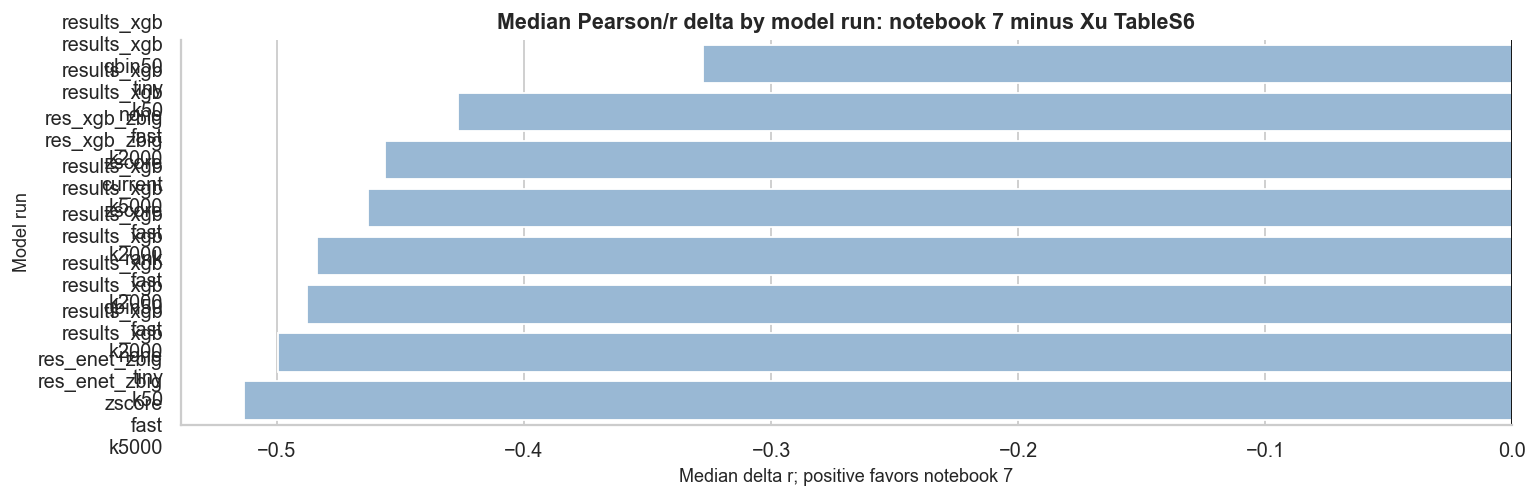

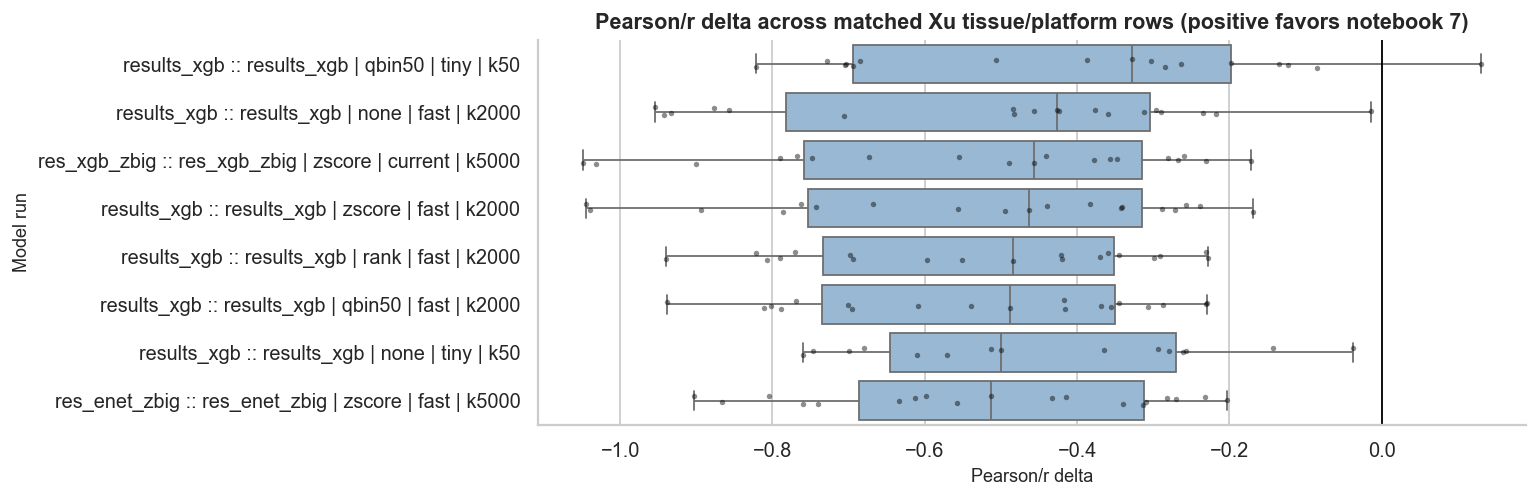

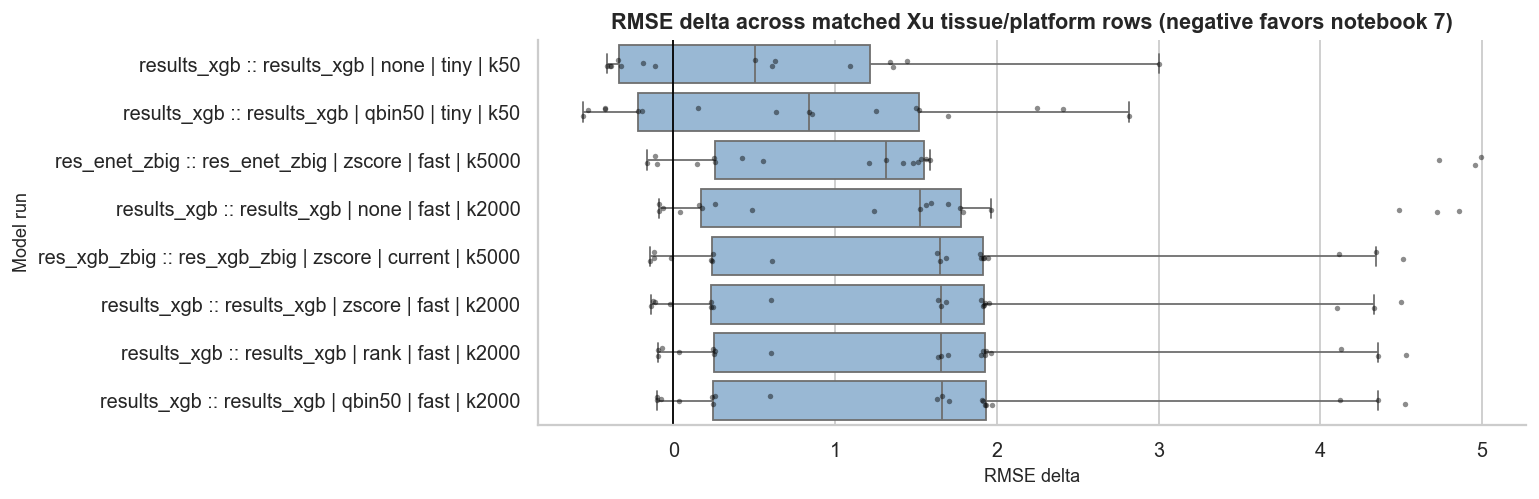

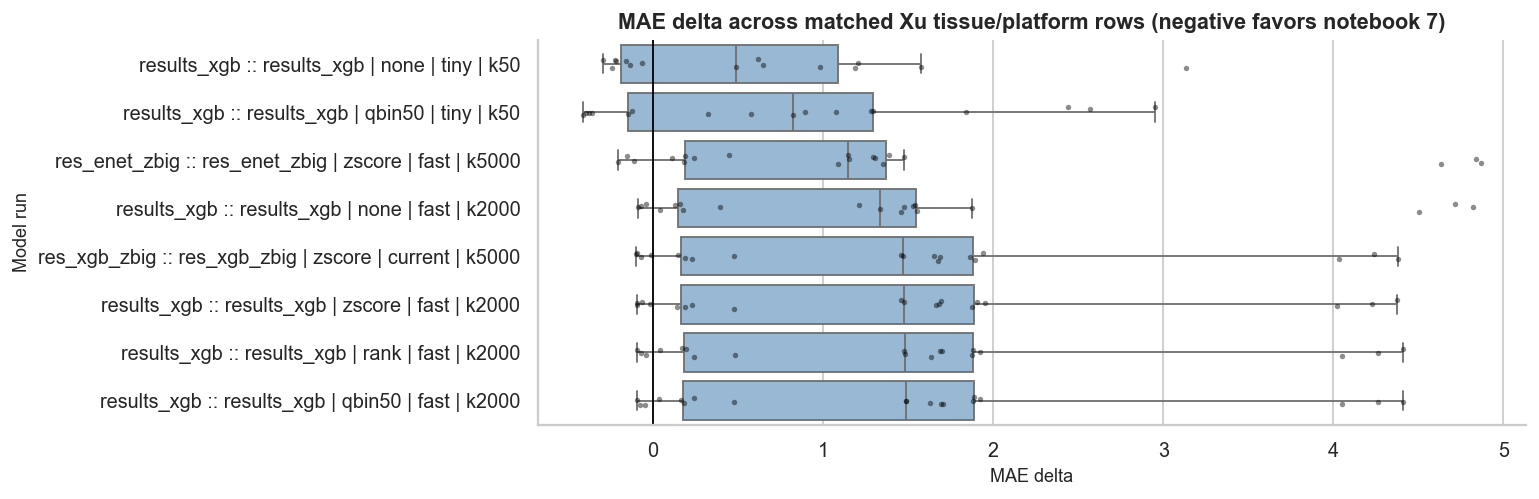

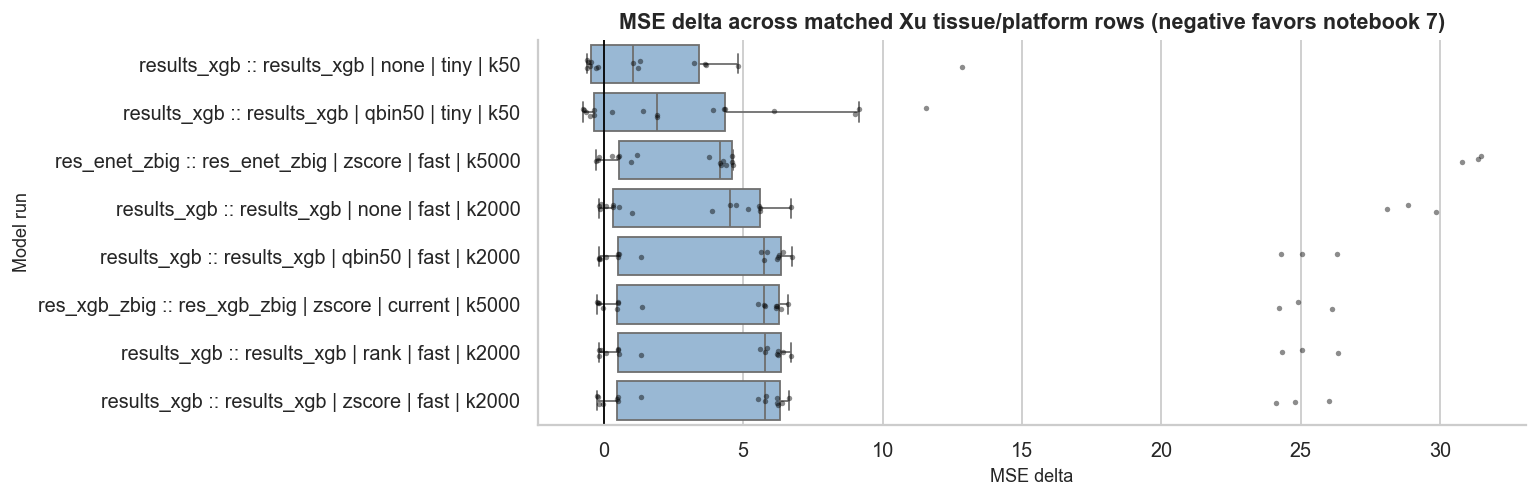

In [11]:
plot_summary = comparison_summary.copy()
plot_summary["model_short"] = plot_summary["model_id"].astype(str).str.replace(" :: ", "\n", regex=False).str.replace(" | ", "\n", regex=False)

fig, ax = plt.subplots(figsize=(12, max(4, 0.38 * len(plot_summary))))
sns.barplot(data=plot_summary, y="model_short", x="median_delta_r", ax=ax, color="#8FB8DE")
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Median Pearson/r delta by model run: notebook 7 minus Xu TableS6")
ax.set_xlabel("Median delta r; positive favors notebook 7")
ax.set_ylabel("Model run")
plt.tight_layout()
plt.show()

for metric, label, better in [
    ("delta_r", "Pearson/r delta", "positive favors notebook 7"),
    ("delta_rmse", "RMSE delta", "negative favors notebook 7"),
    ("delta_mae", "MAE delta", "negative favors notebook 7"),
    ("delta_mse", "MSE delta", "negative favors notebook 7"),
]:
    sub = matched.dropna(subset=[metric]).copy()
    if sub.empty:
        print(f"Skipping {label}: no finite values.")
        continue
    order = sub.groupby("model_id")[metric].median().sort_values(ascending=(metric != "delta_r")).index.tolist()
    fig, ax = plt.subplots(figsize=(12, max(4, 0.38 * len(order))))
    sns.boxplot(data=sub, y="model_id", x=metric, order=order, showfliers=False, ax=ax, color="#8FB8DE")
    sns.stripplot(data=sub, y="model_id", x=metric, order=order, size=3, alpha=0.45, ax=ax, color="black")
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{label} across matched Xu tissue/platform rows ({better})")
    ax.set_xlabel(label)
    ax.set_ylabel("Model run")
    plt.tight_layout()
    plt.show()


## 7. Best-run detailed plots

Focused plots for best median-Pearson-delta model: results_xgb :: results_xgb | qbin50 | tiny | k50


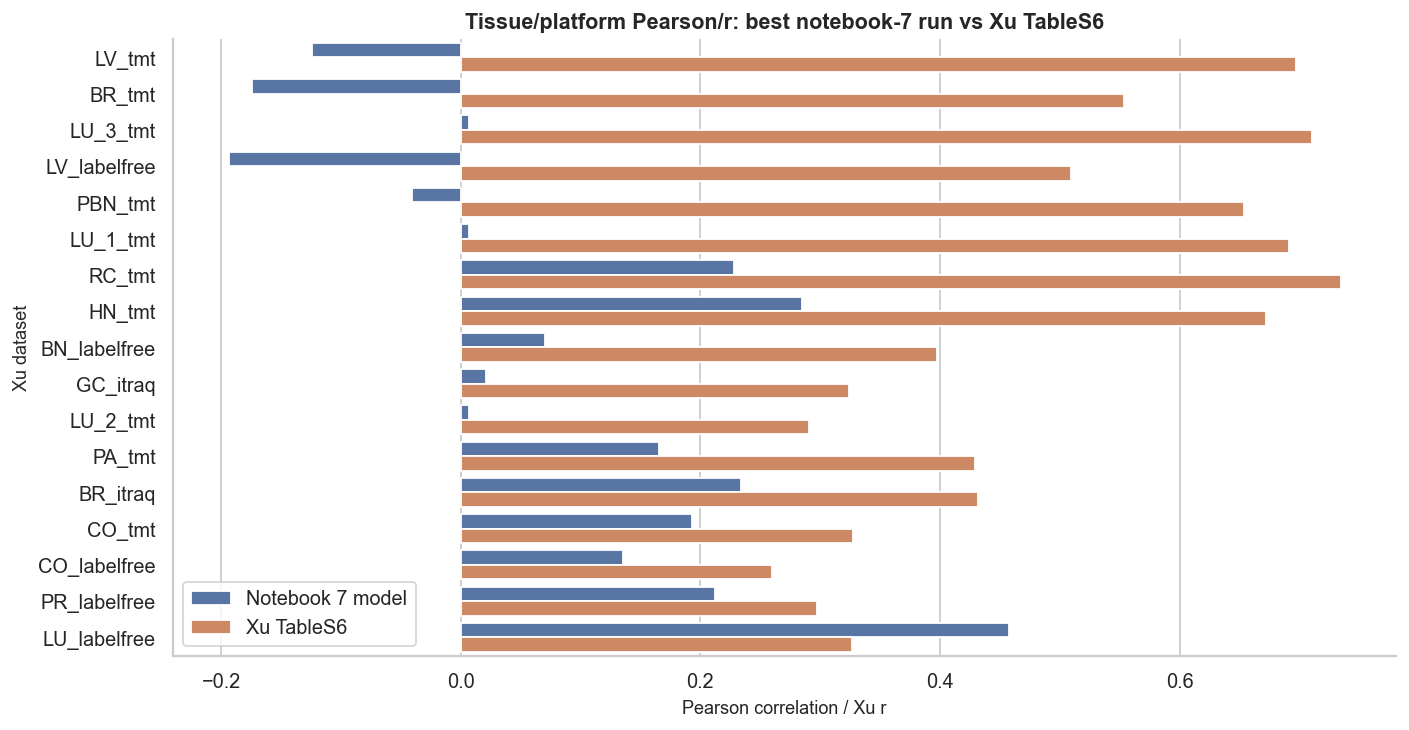

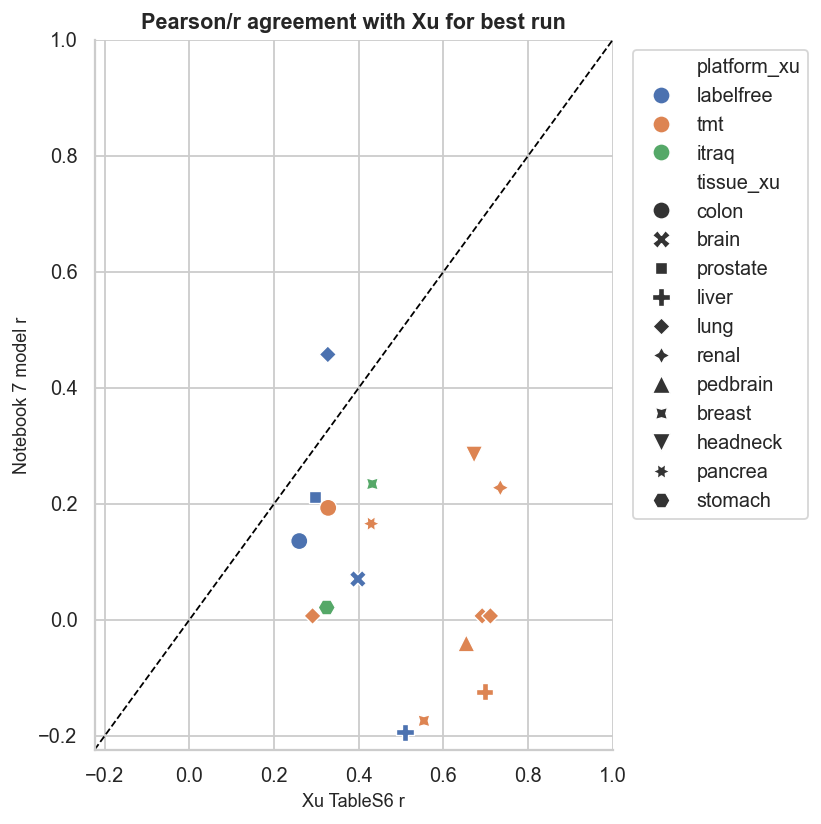

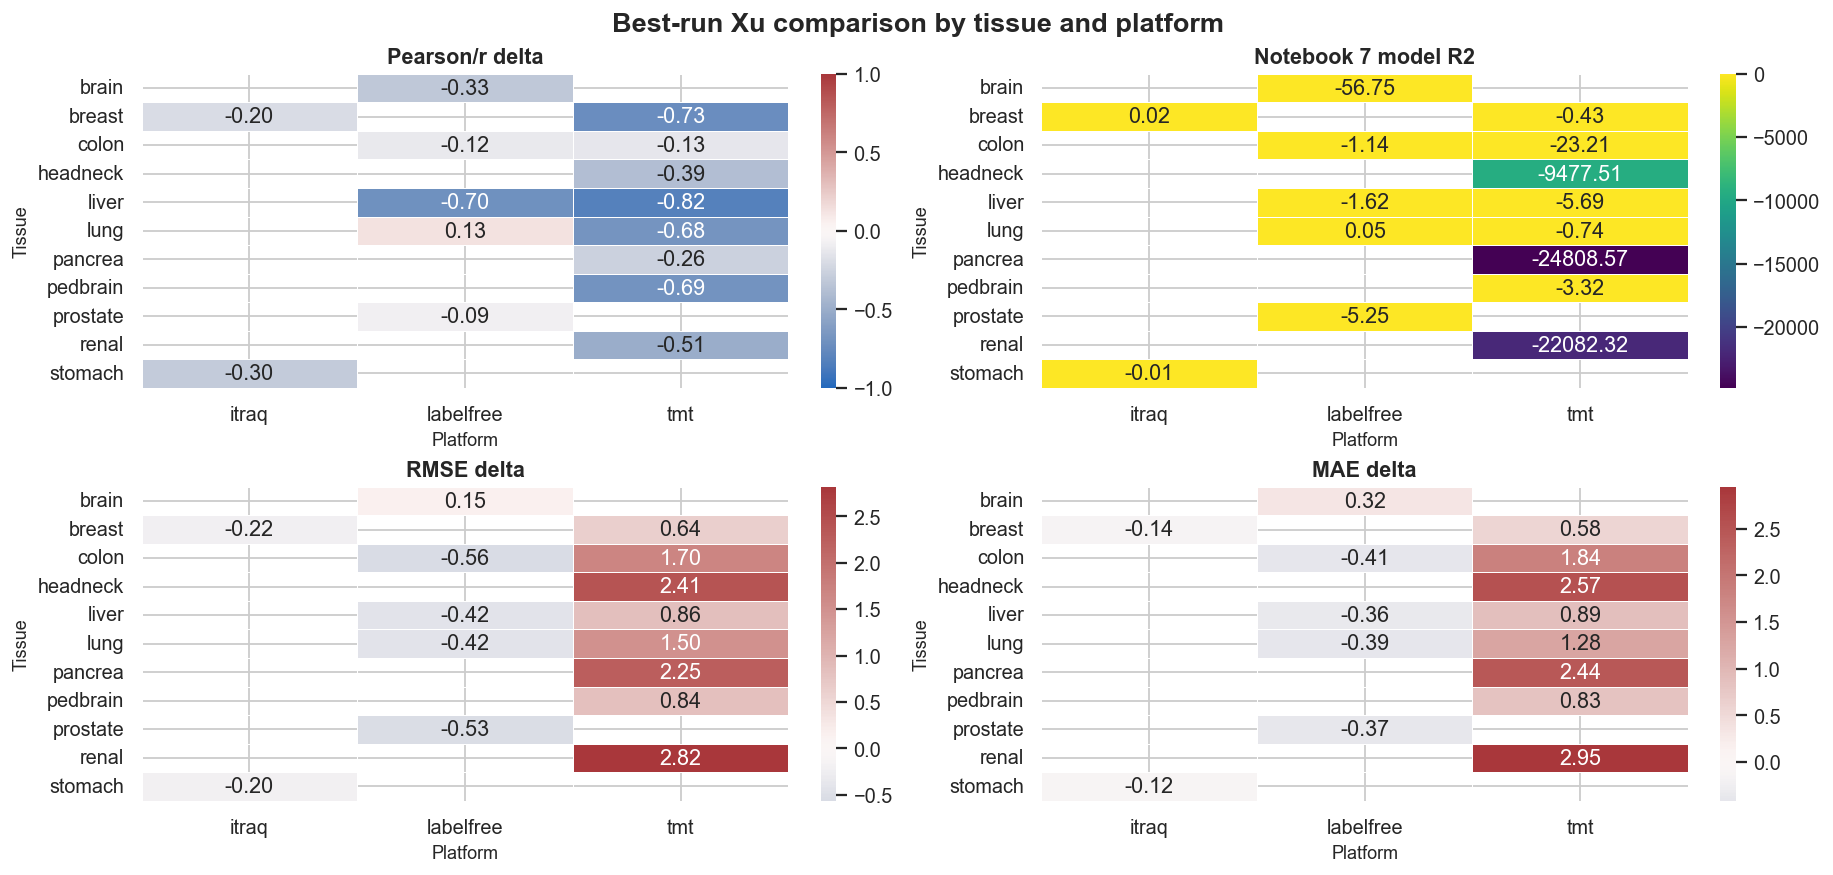

In [12]:
# Pick the best run by median Pearson delta for focused tissue/platform plots.
best_model_id = comparison_summary.iloc[0]["model_id"]
best = matched[matched["model_id"].eq(best_model_id)].copy()
print("Focused plots for best median-Pearson-delta model:", best_model_id)

plot_order = best.sort_values("delta_r", ascending=True)["ShortName_xu"].tolist()

long_r = best[["ShortName_xu", "platform_xu", "tissue_xu", "model_r", "xu_r"]].melt(
    id_vars=["ShortName_xu", "platform_xu", "tissue_xu"],
    value_vars=["model_r", "xu_r"],
    var_name="source",
    value_name="r",
)
long_r["source"] = long_r["source"].map({"model_r": "Notebook 7 model", "xu_r": "Xu TableS6"})
fig, ax = plt.subplots(figsize=(11, max(5, 0.34 * len(plot_order))))
sns.barplot(data=long_r, y="ShortName_xu", x="r", hue="source", order=plot_order, ax=ax)
ax.set_title("Tissue/platform Pearson/r: best notebook-7 run vs Xu TableS6")
ax.set_xlabel("Pearson correlation / Xu r")
ax.set_ylabel("Xu dataset")
ax.legend(title="")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 6.5))
sns.scatterplot(data=best, x="xu_r", y="model_r", hue="platform_xu", style="tissue_xu", s=90, ax=ax)
finite_vals = pd.concat([best["xu_r"], best["model_r"]]).dropna()
if not finite_vals.empty:
    lo = min(-0.05, finite_vals.min() - 0.03)
    hi = max(1.0, finite_vals.max() + 0.03)
    ax.plot([lo, hi], [lo, hi], color="black", linewidth=1, linestyle="--")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
ax.set_title("Pearson/r agreement with Xu for best run")
ax.set_xlabel("Xu TableS6 r")
ax.set_ylabel("Notebook 7 model r")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

metric_specs = [
    ("delta_r", "Pearson/r delta", "vlag", -1, 1),
    ("model_r2", "Notebook 7 model R2", "viridis", None, 1),
    ("delta_rmse", "RMSE delta", "vlag", None, None),
    ("delta_mae", "MAE delta", "vlag", None, None),
]
fig, axes = plt.subplots(2, 2, figsize=(14, max(6, 0.42 * best["tissue_xu"].nunique() + 2.0)), constrained_layout=True)
fig.suptitle("Best-run Xu comparison by tissue and platform", fontsize=15, fontweight="bold")
for ax, (metric, title, cmap, vmin, vmax) in zip(axes.ravel(), metric_specs):
    if metric not in best.columns:
        ax.axis("off")
        ax.set_title(f"{title}\nnot available")
        continue
    pivot = best.pivot_table(index="tissue_xu", columns="platform_xu", values=metric, aggfunc="median")
    sns.heatmap(pivot, ax=ax, cmap=cmap, center=0 if metric.startswith("delta_") else None, linewidths=0.4, linecolor="white", annot=True, fmt=".2f", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("Platform")
    ax.set_ylabel("Tissue")
plt.show()


## 8. Error metric plots for the best run

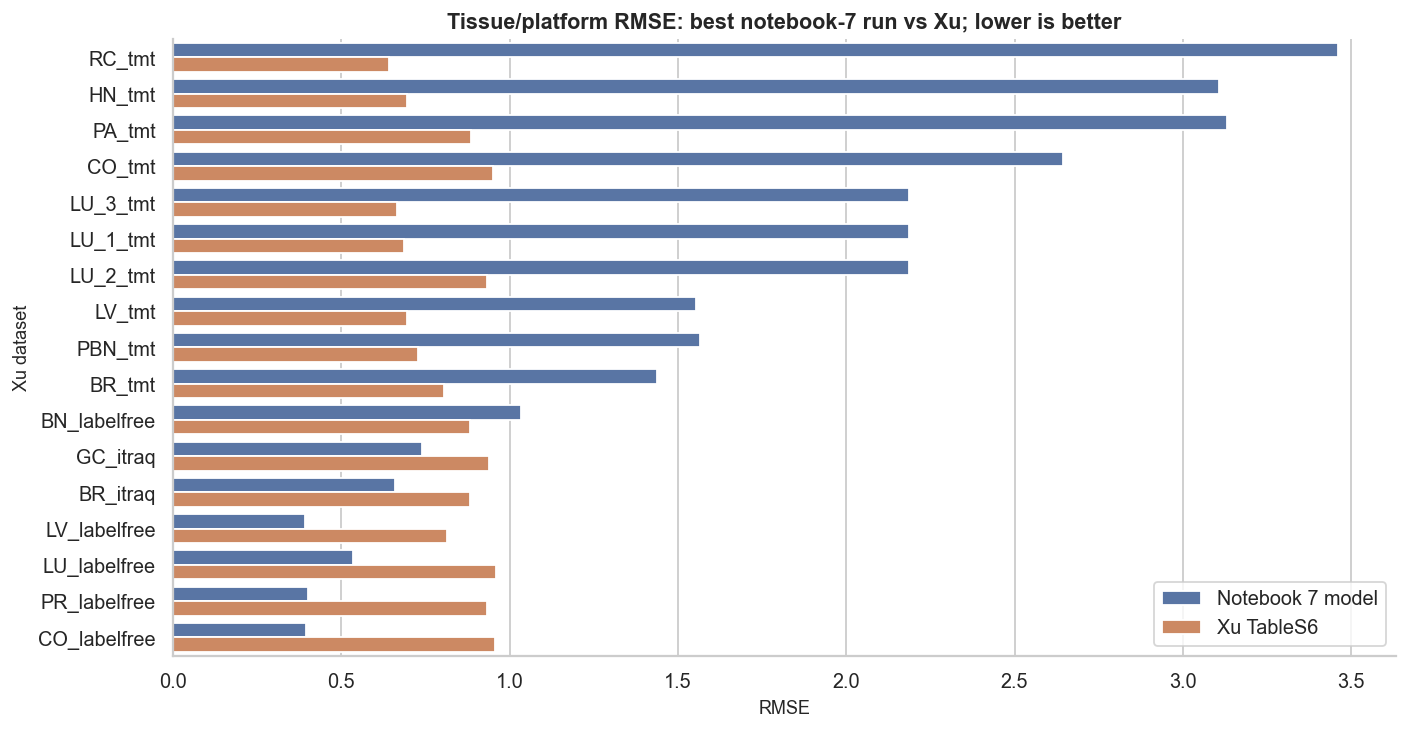

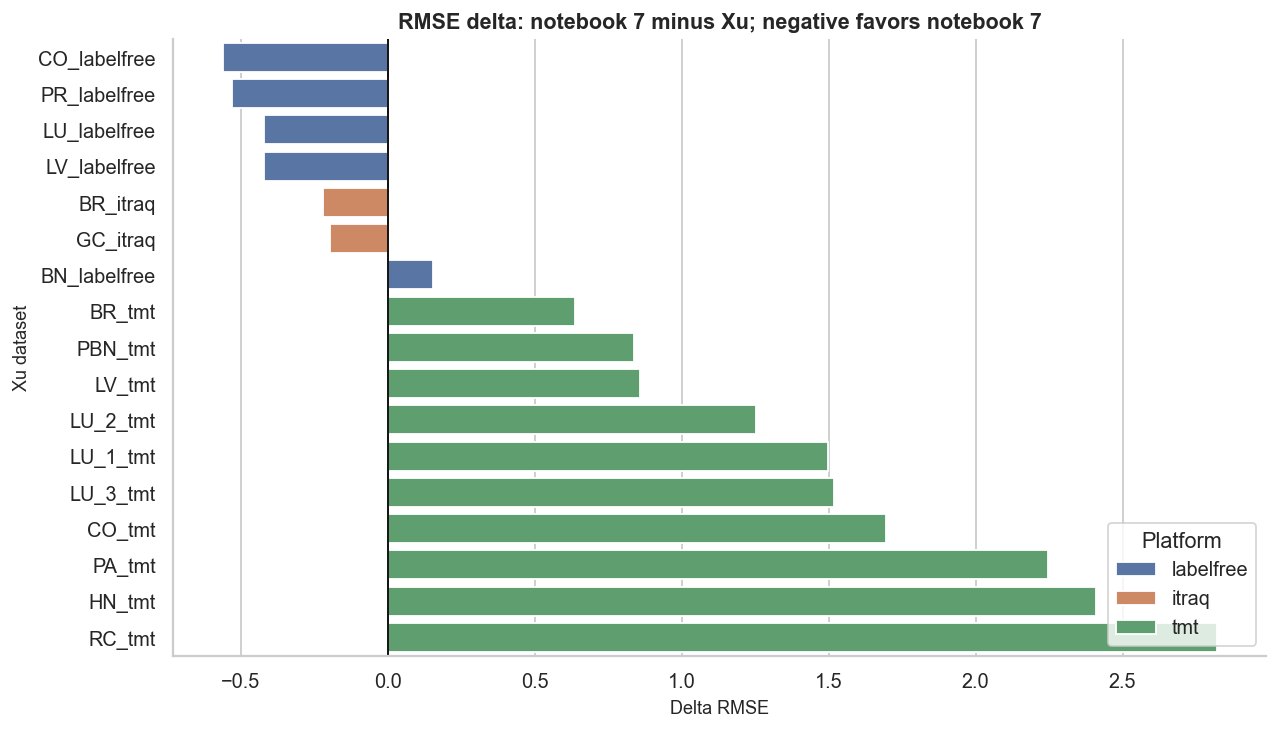

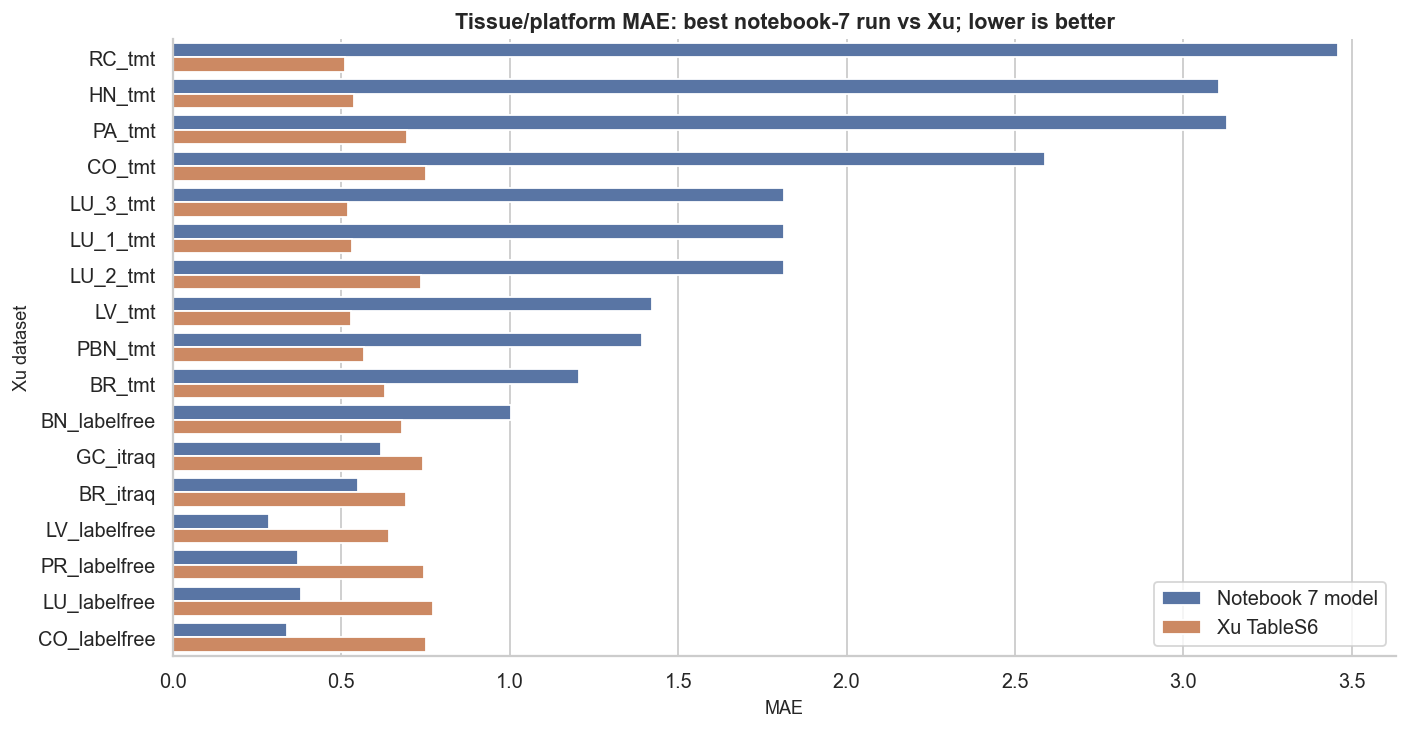

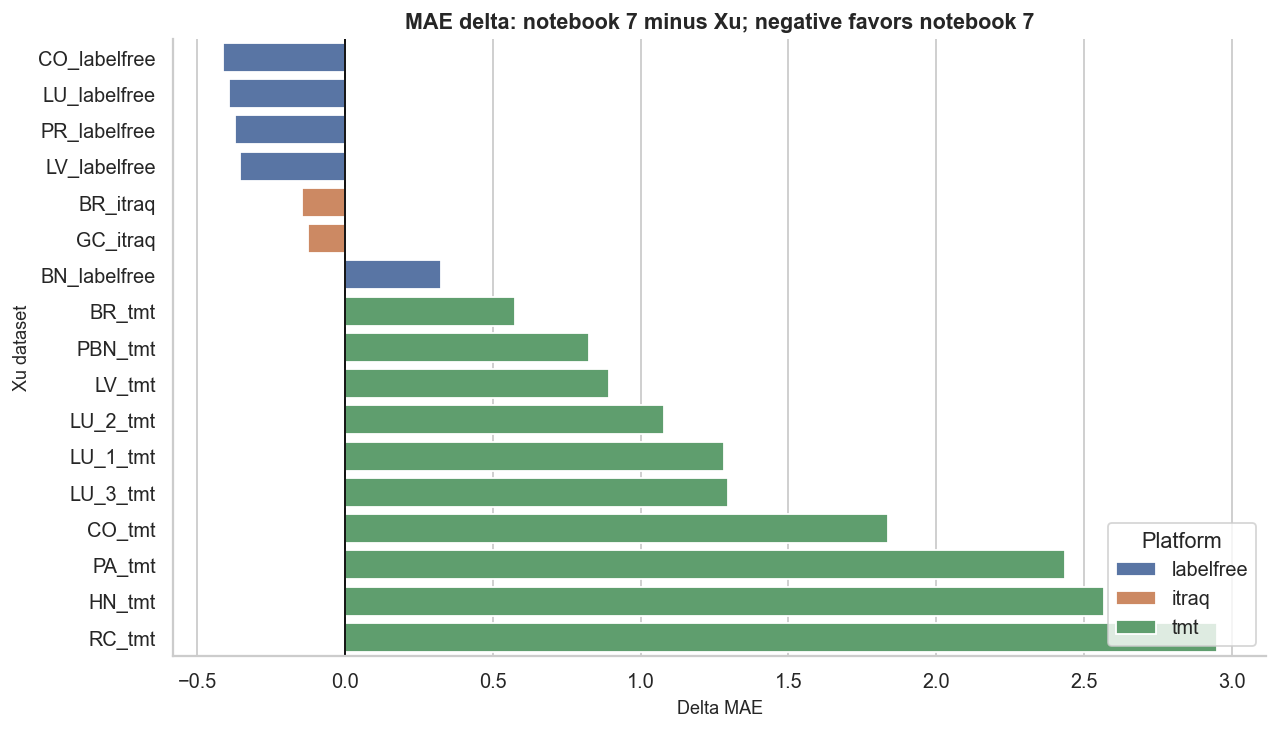

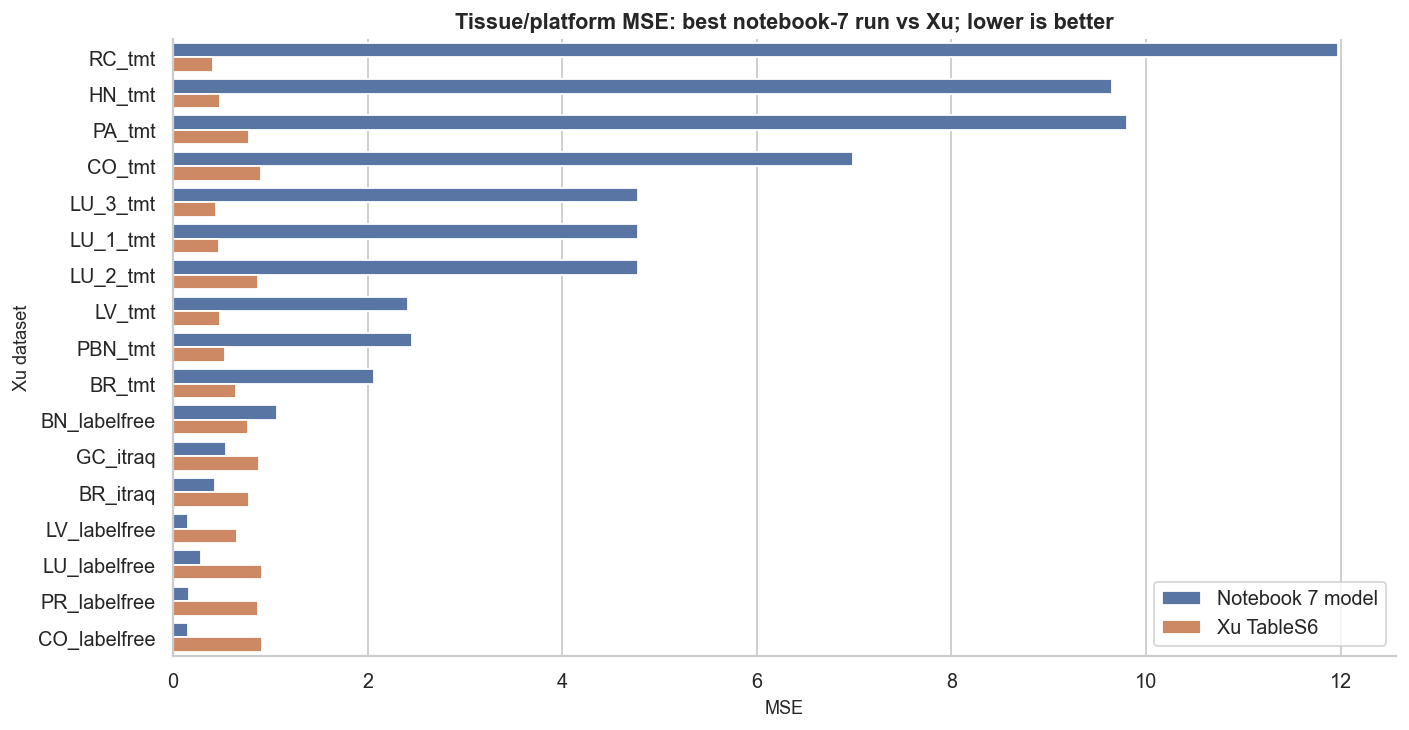

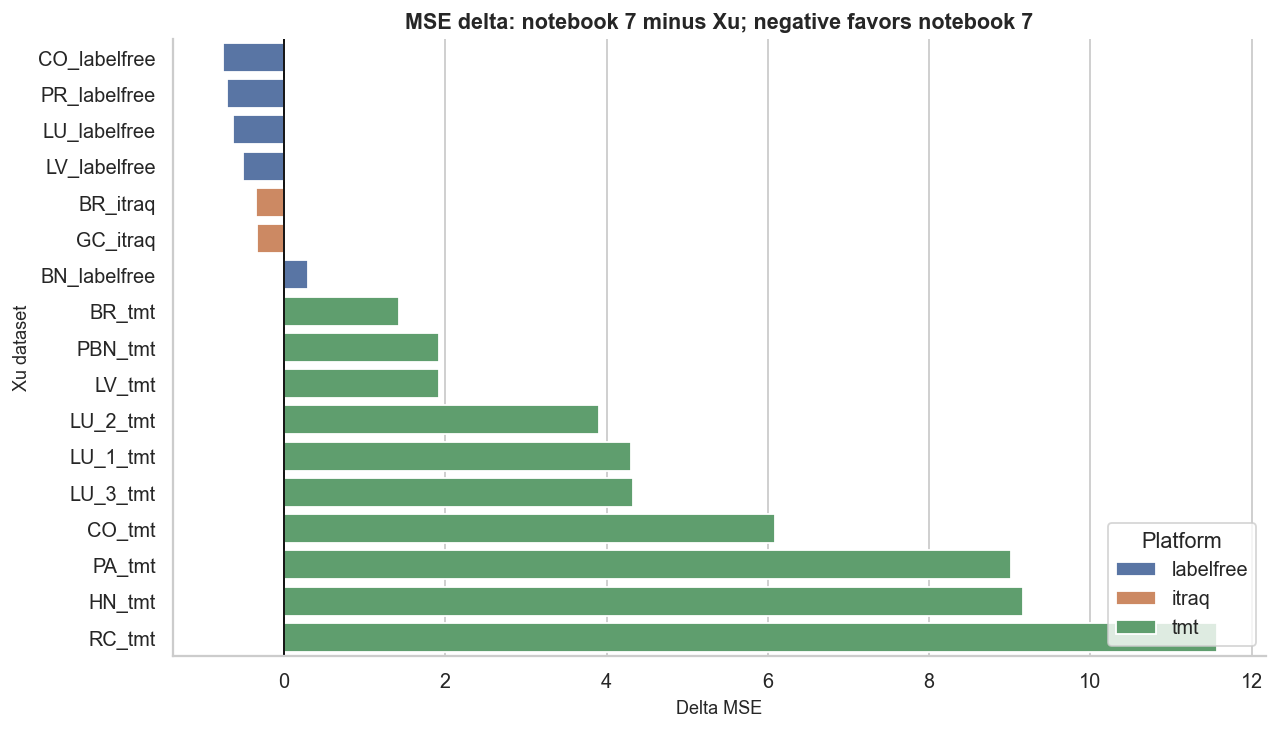

In [13]:
for model_col, xu_col, delta_col, label in [
    ("model_rmse", "xu_rmse", "delta_rmse", "RMSE"),
    ("model_mae", "xu_mae", "delta_mae", "MAE"),
    ("model_mse", "xu_mse", "delta_mse", "MSE"),
]:
    sub = best.dropna(subset=[model_col, xu_col]).copy()
    if sub.empty:
        print(f"Skipping {label}: no finite matched values.")
        continue
    order = sub.sort_values(delta_col, ascending=False)["ShortName_xu"].tolist()
    long = sub[["ShortName_xu", "platform_xu", "tissue_xu", model_col, xu_col]].melt(
        id_vars=["ShortName_xu", "platform_xu", "tissue_xu"],
        value_vars=[model_col, xu_col],
        var_name="source",
        value_name=label,
    )
    long["source"] = long["source"].map({model_col: "Notebook 7 model", xu_col: "Xu TableS6"})
    fig, ax = plt.subplots(figsize=(11, max(5, 0.34 * len(order))))
    sns.barplot(data=long, y="ShortName_xu", x=label, hue="source", order=order, ax=ax)
    ax.set_title(f"Tissue/platform {label}: best notebook-7 run vs Xu; lower is better")
    ax.set_xlabel(label)
    ax.set_ylabel("Xu dataset")
    ax.legend(title="")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(10, max(5, 0.34 * len(order))))
    sns.barplot(data=sub.sort_values(delta_col, ascending=True), y="ShortName_xu", x=delta_col, hue="platform_xu", dodge=False, ax=ax)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{label} delta: notebook 7 minus Xu; negative favors notebook 7")
    ax.set_xlabel(f"Delta {label}")
    ax.set_ylabel("Xu dataset")
    ax.legend(title="Platform", loc="lower right")
    plt.tight_layout()
    plt.show()


## 9. Unmatched diagnostics

In [14]:
print("Unmatched Xu rows. These need a matching notebook-7 tissue/platform or ShortName if they should be compared:")
unmatched_xu_cols = [c for c in ["ShortName", "tissue", "platform", "tissue_key", "platform_key", "shortname_key", "join_key", "samples", "totalprotein"] if c in unmatched_xu.columns]
display(unmatched_xu[unmatched_xu_cols].sort_values([c for c in ["platform", "tissue"] if c in unmatched_xu_cols]) if len(unmatched_xu) else pd.DataFrame(columns=unmatched_xu_cols))

print("Unmatched notebook-7 tissue/model rows. These are available from notebook 7 but not present in Xu TableS6:")
unmatched_model_cols = [c for c in ["ShortName", "tissue", "platform", "model_id", "source_folder", "run_label", "tissue_key", "platform_key", "shortname_key", "join_key", "samples", "common", "r", "rmse", "mae"] if c in unmatched_model.columns]
display(unmatched_model[unmatched_model_cols].sort_values([c for c in ["model_id", "platform", "tissue"] if c in unmatched_model_cols]) if len(unmatched_model) else pd.DataFrame(columns=unmatched_model_cols))


Unmatched Xu rows. These need a matching notebook-7 tissue/platform or ShortName if they should be compared:


,ShortName,tissue,platform,tissue_key,platform_key,shortname_key,join_key,samples,totalprotein
10,EC_tmt,uterus,tmt,uterus,tmt,ec_tmt,tp__uterus__tmt,115,5177


Unmatched notebook-7 tissue/model rows. These are available from notebook 7 but not present in Xu TableS6:


,ShortName,tissue,platform,model_id,source_folder,run_label,tissue_key,platform_key,shortname_key,join_key,samples,common,r,rmse,mae
17,UNKNOWN_tmt,unknown,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,unknown,tmt,unknown_tmt,tp__unknown__tmt,115,2155,0.115922,2.152883,1.950237
35,UNKNOWN_tmt,unknown,tmt,res_xgb_zbig :: res_xgb_zbig | zscore | curren...,res_xgb_zbig,res_xgb_zbig | zscore | current | k5000,unknown,tmt,unknown_tmt,tp__unknown__tmt,115,2155,0.221154,2.556867,2.434646
53,UNKNOWN_tmt,unknown,tmt,results_xgb :: results_xgb | none | fast | k2000,results_xgb,results_xgb | none | fast | k2000,unknown,tmt,unknown_tmt,tp__unknown__tmt,115,2155,-0.267777,2.207842,1.997434
71,UNKNOWN_tmt,unknown,tmt,results_xgb :: results_xgb | none | tiny | k50,results_xgb,results_xgb | none | tiny | k50,unknown,tmt,unknown_tmt,tp__unknown__tmt,115,1,-0.017238,1.537633,1.371191
89,UNKNOWN_tmt,unknown,tmt,results_xgb :: results_xgb | qbin50 | fast | k...,results_xgb,results_xgb | qbin50 | fast | k2000,unknown,tmt,unknown_tmt,tp__unknown__tmt,115,2155,0.052875,2.561071,2.415917
107,UNKNOWN_tmt,unknown,tmt,results_xgb :: results_xgb | qbin50 | tiny | k50,results_xgb,results_xgb | qbin50 | tiny | k50,unknown,tmt,unknown_tmt,tp__unknown__tmt,115,1,-0.053554,1.823722,1.667663
125,UNKNOWN_tmt,unknown,tmt,results_xgb :: results_xgb | rank | fast | k2000,results_xgb,results_xgb | rank | fast | k2000,unknown,tmt,unknown_tmt,tp__unknown__tmt,115,2155,0.060858,2.563268,2.417406
143,UNKNOWN_tmt,unknown,tmt,results_xgb :: results_xgb | zscore | fast | k...,results_xgb,results_xgb | zscore | fast | k2000,unknown,tmt,unknown_tmt,tp__unknown__tmt,115,2155,0.212212,2.568036,2.445351


## 10. Exports

In [15]:
xu.to_csv(OUT_DIR / "xu_tableS6_summary_clean.csv", index=False)
model.to_csv(OUT_DIR / "notebook7_tissue_metrics_tableS6_format_used.csv", index=False)
model_unique.to_csv(OUT_DIR / "notebook7_tissue_metrics_unique_by_run.csv", index=False)
comparison.to_csv(OUT_DIR / "notebook7_tissue_vs_xu_all_rows.csv", index=False)
matched.to_csv(OUT_DIR / "notebook7_tissue_vs_xu_matched.csv", index=False)
unmatched_xu.to_csv(OUT_DIR / "unmatched_xu_rows_for_notebook7_tissue_comparison.csv", index=False)
unmatched_model.to_csv(OUT_DIR / "unmatched_notebook7_tissue_rows_for_xu_comparison.csv", index=False)
comparison_summary.to_csv(OUT_DIR / "notebook7_vs_xu_summary_by_model_run.csv", index=False)
best_by_r.to_csv(OUT_DIR / "best_notebook7_model_per_xu_row_by_r.csv", index=False)
best_by_rmse.to_csv(OUT_DIR / "best_notebook7_model_per_xu_row_by_rmse.csv", index=False)

print("Saved Xu comparison outputs to:", OUT_DIR)
print("- xu_tableS6_summary_clean.csv")
print("- notebook7_tissue_metrics_tableS6_format_used.csv")
print("- notebook7_tissue_metrics_unique_by_run.csv")
print("- notebook7_tissue_vs_xu_all_rows.csv")
print("- notebook7_tissue_vs_xu_matched.csv")
print("- unmatched_xu_rows_for_notebook7_tissue_comparison.csv")
print("- unmatched_notebook7_tissue_rows_for_xu_comparison.csv")
print("- notebook7_vs_xu_summary_by_model_run.csv")
print("- best_notebook7_model_per_xu_row_by_r.csv")
print("- best_notebook7_model_per_xu_row_by_rmse.csv")


Saved Xu comparison outputs to: C:\Users\hp\Desktop\new_pRNA\xu_comparison_outputs
- xu_tableS6_summary_clean.csv
- notebook7_tissue_metrics_tableS6_format_used.csv
- notebook7_tissue_metrics_unique_by_run.csv
- notebook7_tissue_vs_xu_all_rows.csv
- notebook7_tissue_vs_xu_matched.csv
- unmatched_xu_rows_for_notebook7_tissue_comparison.csv
- unmatched_notebook7_tissue_rows_for_xu_comparison.csv
- notebook7_vs_xu_summary_by_model_run.csv
- best_notebook7_model_per_xu_row_by_r.csv
- best_notebook7_model_per_xu_row_by_rmse.csv
